# Create Easy Dataset

In this notebook, we generate a simulated "easy" EEG dataset. The simulation includes a signal for active dipoles and a background signal. The user can define a range for the number of dipoles with the active signal, and the remaining dipoles will contain only the background signal. Additionally, the user can select a range for the EEG signal-to-noise ratio (SNR), so that the variance of the background signal is adjusted to ensure the EEG SNR falls within the specified range.

I have divided this notebook into three sections:

1. Visualize the head model to be used.
2. Inspect the simulation model and determine the appropriate ranges for the number of dipoles and EEG SNR.
3. Generate the dataset.

For each section, you will need to run the '📦 Imports' and '🧠 Data' cells first. After that, the three sections are independent of each other.

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
from pathlib import Path

## 🧠 Data

In [2]:
# configuration
sub = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")

# data
data  = mm.io.read_dataset(sub, "eeg_coreg", "fwd_hr", "parc", "cras", "white", "bem")
sfreq = data["eeg_coreg"].info["sfreq"]

A = mne.convert_forward_solution(data["fwd_hr"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]                                                                                    # forward matrix

vertices  = np.vstack([data["white"][0][0], data["white"][1][0]])
triangles = np.vstack([data["white"][0][1], data["white"][1][1]+len(data["white"][0][0])])
neighbors = mm.utils.find_neighbor_regions([vertices, triangles], data["parc"], data["cras"])           # region neighbors

regions = data["parc"].get_clut()["Label name"].values                                                  # region ids
pos     = mm.utils.get_src_position(data["fwd_hr"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)                                                                # dipole labels

# parameters
duration = 1            # duration in seconds

#### Utilities

In [3]:
def grow_patch(starting_roi, n):
    """
    Grow patch starting at region and including neighbors until having n neighbors. 
    """    

    regions_idx = set(np.argwhere(regions==starting_roi)[0])

    while len(regions_idx) < n:
        neighborhood = neighbors[np.random.choice(list(regions_idx))]
        neighbor_idx = np.argwhere(neighborhood==1).squeeze()

        new_idx = np.random.choice(neighbor_idx)
    
        if regions[new_idx] in labels:
            regions_idx.add(new_idx)

    roi      = regions[list(regions_idx)]
    roi_mask = np.isin(labels, roi)

    return roi_mask

## Section 1: Visualize Head Model

#### 🌟 EEG Coregistration

In [4]:
pos  = mm.utils.get_ch_positions(data["eeg_coreg"])
head = data["bem"][0]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(pos), color="red")
plotter.add_mesh(mm.utils.surf_to_polydata(head["rr"], head["tris"]))
plotter.show()

Widget(value='<iframe src="http://localhost:41139/index.html?ui=P_0x794916199fd0_0&reconnect=auto" class="pyvi…

#### 🌟 Forward Solution

In [5]:
mm.viz.plot_leadfield(data["eeg_coreg"], data["fwd_hr"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:41139/index.html?ui=P_0x79491619a9c0_1&reconnect=auto" class="pyvi…

## Section 2: Inspect Simulation

We found the following link between the EEG SNR of an electrode and the active/background dipoles: $$EEG_{snr} = 10\cdot \log_{10}\left( \frac{\vec a^\intercal \Sigma^a \vec a}{\vec a^\intercal\Sigma^b\vec a}\right)$$where $\Sigma^a$ and $\Sigma^b$ are the covariance matrices of the active dipoles and background dipoles respectively. $\vec a$ is the lead field vector of the electrode. <br>

In this simulation, the background is a gaussian noise meaning that the covariance matrix of background dipoles is: $$\Sigma = \begin{bmatrix}\sigma^2 & 0 & \cdots \\
0 & \sigma ^2 & \cdots \\ \vdots & \vdots & \ddots\end{bmatrix}$$The relation between the variance of our noise and the final EEG SNR is obtained through simplifying the first equation with the Gaussian covariance matrix: $$\sigma^2 = \frac{\vec a^\intercal \Sigma^a \vec a}{\sum_{i=1}^n a_i^2} \cdot10^{-EEG_{snr}/10}$$

In part 1 we test a single simulation and see if our prediciton works. Naturally, there will be some uncertainty due to the uncertainty of noise. In part 2 we simulate a high number of times to evaluate this uncertainty.

#### Part 1: Single simulation

#### 🌟 Print list of brain regions

In [6]:
print("\033[94mList of regions: \033[0m")
print(np.unique(labels))

List of regions: 
['ctx-lh-bankssts_1' 'ctx-lh-bankssts_2' 'ctx-lh-bankssts_3'
 'ctx-lh-caudalanteriorcingulate_1' 'ctx-lh-caudalanteriorcingulate_2'
 'ctx-lh-caudalanteriorcingulate_3' 'ctx-lh-caudalmiddlefrontal_1'
 'ctx-lh-caudalmiddlefrontal_2' 'ctx-lh-caudalmiddlefrontal_3'
 'ctx-lh-caudalmiddlefrontal_4' 'ctx-lh-caudalmiddlefrontal_5'
 'ctx-lh-cuneus_1' 'ctx-lh-cuneus_2' 'ctx-lh-cuneus_3' 'ctx-lh-cuneus_4'
 'ctx-lh-entorhinal_1' 'ctx-lh-frontalpole_1' 'ctx-lh-fusiform_1'
 'ctx-lh-fusiform_2' 'ctx-lh-fusiform_3' 'ctx-lh-fusiform_4'
 'ctx-lh-fusiform_5' 'ctx-lh-fusiform_6' 'ctx-lh-fusiform_7'
 'ctx-lh-fusiform_8' 'ctx-lh-inferiorparietal_1'
 'ctx-lh-inferiorparietal_10' 'ctx-lh-inferiorparietal_11'
 'ctx-lh-inferiorparietal_12' 'ctx-lh-inferiorparietal_2'
 'ctx-lh-inferiorparietal_3' 'ctx-lh-inferiorparietal_4'
 'ctx-lh-inferiorparietal_5' 'ctx-lh-inferiorparietal_6'
 'ctx-lh-inferiorparietal_7' 'ctx-lh-inferiorparietal_8'
 'ctx-lh-inferiorparietal_9' 'ctx-lh-inferiortemporal_1'
 '

#### 🛠️ <font color=violet>Select a region and number of regions</font>
- The region (`starting_roi`) defines the location of the patch
- The number of regions (`n`) will roughtly define the patch size

In [7]:
starting_roi = "ctx-lh-inferiorparietal_5"
n = 3

#### ⚙️ <font color=green>Grow patch around selected region</font>

In [8]:
roi_mask = grow_patch(starting_roi, n)

#### 🛠️ <font color=violet>Select ratio between signal and background</font>
Background activity correspond to white noise while the signal is a standardized mexican hat.

In [9]:
eeg_snr = 10

#### ⚙️ <font color=green>Generate Simulated Data

In [10]:
# active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*10**(-8)    # scale to nA

Xa = np.repeat(signal.reshape(1,-1), np.sum(roi_mask), axis=0)

# compute average power of projected active dipoles
cova = np.cov(Xa)
Pa   = np.diagonal(A[:,roi_mask] @ cova @ A[:,roi_mask].T)
idx  = np.argmax(Pa)                                         # electrode with highest active power

# background dipoles
var = Pa[idx]/np.sum(A[idx,~roi_mask]**2) * 10**(-eeg_snr/10)
Xb  = np.random.normal(scale=np.sqrt(var), size=(np.sum(~roi_mask), int(sfreq*duration)))

# create ground truth
brain_activity = np.zeros((len(roi_mask),int(sfreq*duration)))
brain_activity[roi_mask]  = Xa 
brain_activity[~roi_mask] = Xb

vertices       = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]
brain_activity = mne.SourceEstimate(brain_activity, vertices, tmin=0, tstep=1/sfreq, subject=sub)

# Generate EEGs
eeg = mne.apply_forward(data["fwd_hr"], brain_activity, data["eeg_coreg"].info, verbose="warning")

#### 🌟 Visualize dipole signals

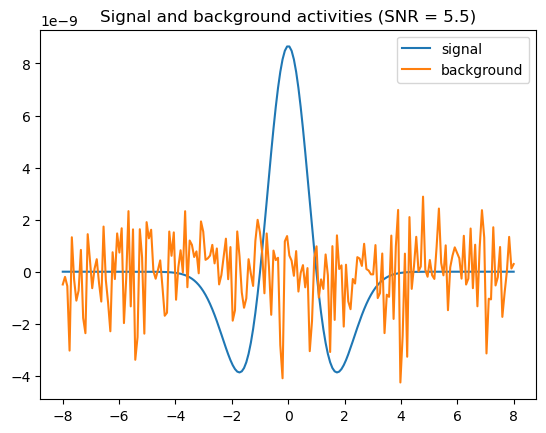

In [11]:
ab_snr = mm.utils.compute_snr(Xa[0,:], Xb[0,:])         # snr between one active dipole and one active dipole

ax1 = sns.lineplot(x=time, y=Xa[0,:], label="signal")
ax2 = sns.lineplot(x=time, y=Xb[0,:], label="background")
_   = ax1.set_title(f"Signal and background activities (SNR = {ab_snr[0]:.2})")

#### 🌟 Visualize ground truth

In [12]:
source_snr = mm.utils.compute_snr(np.sum(Xa, axis=0), np.sum(Xb, axis=0))

print(f"Source SNR: {source_snr[0]:.3}")
mm.viz.plot_brain_time_series(data["fwd_hr"]["src"], brain_activity.data, sfreq=sfreq, cmap="bwr")

Source SNR: 3.51


Widget(value='<iframe src="http://localhost:41139/index.html?ui=P_0x7948e4514680_2&reconnect=auto" class="pyvi…

#### 🌟 Visualize EEG

EEG SNR: 9.95


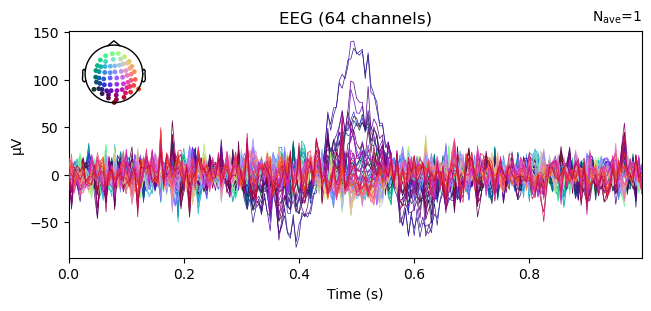

In [13]:
#%matplotlib qt

EEGa = A[:,roi_mask] @ Xa 
EEGb = A[:,~roi_mask] @ Xb 
snr  = mm.utils.compute_snr(EEGa, EEGb)

print(f"EEG SNR: {snr[idx]:.3}")
_ = eeg.plot()

SNR topomap
Minimum SNR: -23.21972589902531
Maximum SNR: 10.465517555509713


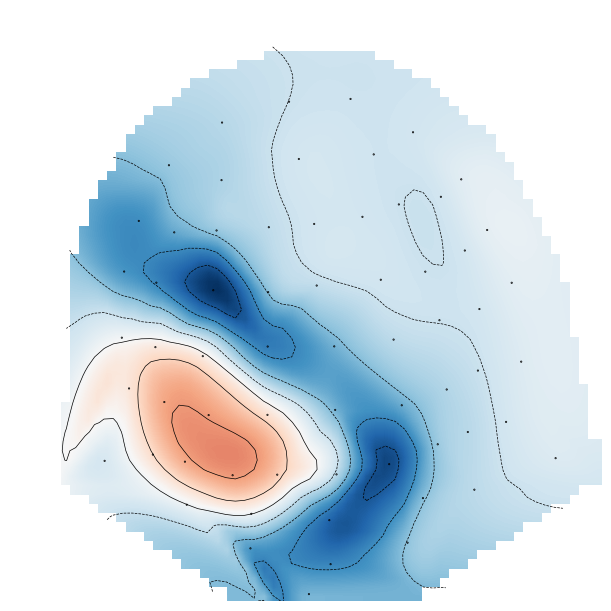

In [17]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(snr)}")
print(f"Maximum SNR: {np.max(snr)}")
_ = mne.viz.plot_topomap(snr, data["eeg_coreg"].info, size=6, outlines=None, extrapolate="local")

#### Part 2: Uncertainty
🚨 Run cell '📦 imports' and '🧠 data' before continuing. 

Here we run the simulation multiple times for various patch locations and patch sizes.

#### 🛠️ <font color=violet>Select loop parameters</font>

In [43]:
rg_snr       = [0, 10]      # range for EEG SNR
rg_n_dipoles = [20, 100]    # range for the number of active dipoles
rep          = 3000         # number of repetition

#### Preparing data

In [44]:
# storage
target_snr = np.zeros(rep)                                     
true_snr   = np.zeros((rep, len(data["eeg_coreg"].ch_names)))

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# dipole distance matrix (to grow dipole patch)
dist = [
    data["fwd_hr"]["src"][0]["dist"][vertno[0]][:,vertno[0]], 
    data["fwd_hr"]["src"][1]["dist"][vertno[1]][:,vertno[1]],
]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*10**(-8)    # scale to nA

# functions to compute average power of EEGa and estimate variance
compute_Pa  = lambda Xa, roi_mask: np.diagonal(A[:,roi_mask] @ np.cov(Xa) @ A[:,roi_mask].T)
compute_var = lambda snr, Pa, a: Pa / np.sum(a**2) * 10**(-snr/10)

#### ⚙️ <font color=green>Loop through simulations</font>

In [45]:
for i in range(rep):
    # select state
    snr = np.random.uniform(rg_snr[0], rg_snr[1])
    n   = np.random.randint(rg_n_dipoles[0], rg_n_dipoles[1])

    # generate patch
    hemi            = np.random.choice([0,1])                    # choose hemisphere (left or right)
    starting_dipole = np.random.choice(vertno[hemi])             # choose starting dipole
    starting_idx    = np.argwhere(vertno[hemi]==starting_dipole)[0]
    
    ddist = dist[hemi][starting_idx].todense().squeeze()    # distance between dipoles and selected dipole
    roi   = np.argsort(ddist)[:n]                           # choose n closest dipoles (includes selected dipole)
    
    if hemi == 1: 
        roi = roi + data["fwd_hr"]["src"][0]["nuse"]        # roi index of right hemisphere start after left hemisphere

    roi_mask = np.zeros(data["fwd_hr"]["nsource"], dtype=bool)
    roi_mask[roi] = True
    
    # active dipoles
    Xa = np.repeat(signal.reshape(1,-1), np.sum(roi_mask), axis=0)
    Pa = compute_Pa(Xa, roi_mask)

    # background dipoles
    idx = np.argmax(Pa)
    a   = A[idx,~roi_mask]
    var = compute_var(snr, Pa[idx], a)

    Xb  = np.random.normal(scale=np.sqrt(var), size=(np.sum(~roi_mask), int(sfreq*duration)))

    # EEG SNR
    EEGa    = A[:,roi_mask] @ Xa 
    EEGb    = A[:,~roi_mask] @ Xb 
    eeg_snr = mm.utils.compute_snr(EEGa, EEGb)

    # store variance and EEG SNR
    target_snr[i] = snr
    true_snr[i,:] = eeg_snr

#### 🌟 Visualize distributions

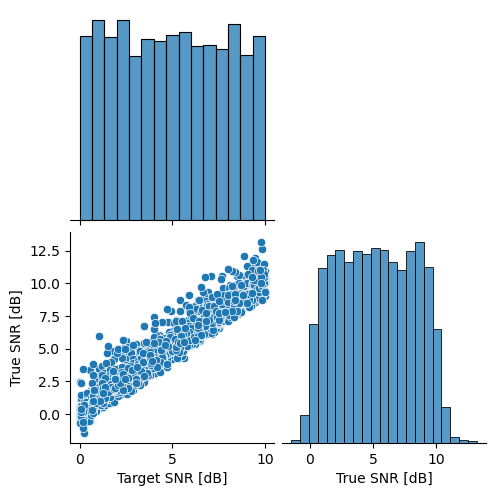

In [46]:
true_snr_max = np.max(true_snr, axis=1)
results      = pd.DataFrame({"True SNR [dB]":true_snr_max, "Target SNR [dB]":target_snr})

_  = sns.pairplot(
    results, 
    x_vars = ["Target SNR [dB]", "True SNR [dB]"],
    y_vars = ["Target SNR [dB]","True SNR [dB]"],
    corner = True,
)

## Section 3: Create Dataset
🚨 Run cell '📦 imports' and '🧠 data' before continuing.

#### Dataset Propreties

In [45]:
# data info
name      = "Clean EEG"                                         # name of dataset
folder    = Path(config["DS_DIR"])/"derivatives"/"cleanEEG"     # folder to save data (pathlib Path)
n_samples = 20                                                  # number of samples

# sample properties
snr_range      = [20,21]     # range for the EEG SNR
n_region_range = [1,3]       # range for the number of active regions
duration       = 1           # duration in [s]

#### Preparations ...

In [46]:
# check folder existence
if folder.exists():
    raise FileExistsError(f"\033[91mFolder '{folder}' already exists.")
else:
    folder.mkdir(parents=True)

# vertno (to instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# signal for active dipoles
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*10**(-8)    # scale to nA

# functions to compute average power of EEGa and estimate variance
compute_Pa  = lambda Xa, roi_mask: np.diagonal(A[:,roi_mask] @ np.cov(Xa) @ A[:,roi_mask].T)
compute_var = lambda snr, Pa, a: Pa / np.sum(a**2) * 10**(-snr/10)

#### ⚙️ <font color=green>Generate dataset</font>

In [47]:
folder = Path(folder)

for i in range(n_samples):

    # Select random snr/location/size
    snr          = np.random.uniform(snr_range[0], snr_range[1])
    n            = np.random.randint(n_region_range[0], n_region_range[1])
    starting_roi = np.random.choice(np.unique(labels))

    # generate patch
    roi_mask = grow_patch(starting_roi, n)
    
    # active dipoles
    Xa = np.repeat(signal.reshape(1,-1), np.sum(roi_mask), axis=0)
    Pa = compute_Pa(Xa, roi_mask)

    # background dipoles
    idx = np.argmax(Pa)
    a   = A[idx,~roi_mask]
    var = compute_var(snr, Pa[idx], a)

    Xb  = np.random.normal(scale=np.sqrt(var), size=(np.sum(~roi_mask), int(sfreq*duration)))

    # create ground truth
    brain_activity = np.zeros((len(roi_mask),int(sfreq*duration)))
    brain_activity[roi_mask]  = Xa 
    brain_activity[~roi_mask] = Xb

    vertices       = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]
    brain_activity = mne.SourceEstimate(brain_activity, vertices, tmin=0, tstep=1/sfreq, subject=sub)

    # Generate EEGs
    eeg = mne.apply_forward(data["fwd_hr"], brain_activity, data["eeg_coreg"].info, verbose="warning")

    # save simulation
    fsample = folder/f"sample{i+1}"
    fsample.mkdir()

    brain_activity.save(fsample/f"{sub}_sample{i}_stc.fif", verbose="warning")
    eeg.save(fsample/f"{sub}_sample{i}_ave.fif", verbose="warning")


# create info file
text = f"""
    Name: {name} \n
    Subject: {sub} \n
    Duration: {duration} seconds [s]\n
    Range for the EEG SNR: {snr_range} decibels [dB]\n
    Range for the number of active regions: {n_region_range}\n
    """

with open(folder/"info.txt", "w") as file:
    file.write(text)